# 1. Download data

I started the docker container using the following command in my terminal:

```bash
docker run -d --name hw2-postgres \
  -e POSTGRES_USER=postgres -e POSTGRES_PASSWORD=postgres -e POSTGRES_DB=trains \
  -p 5432:5432 -v hw2_pgdata:/var/lib/postgresql/data postgres:17
```

In [1]:
!mkdir -p data/disruptions data/services

In [2]:
!curl -o data/tariff-distances-2022-01.csv https://opendata.rijdendetreinen.nl/public/tariff-distances/tariff-distances-2022-01.csv
!curl -o data/stations-2023-09.csv https://opendata.rijdendetreinen.nl/public/stations/stations-2023-09.csv

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  56 0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     09k  100  569k    0     0  2966k      0 --:--:-- --:--:-- --:--:-- 2968k
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 65007  100 65007    0     0   560k      0 --:--:-- --:--:-- --:--:--  556k


In [3]:
%%bash

for y in $(seq 2011 2023); do
  curl -o data/disruptions/disruptions-$y.csv https://opendata.rijdendetreinen.nl/public/disruptions/disruptions-$y.csv
done

for y in $(seq 2019 2025); do
  curl -o data/services/services-$y.csv.gz https://opendata.rijdendetreinen.nl/public/services/services-$y.csv.gz
done

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  400k  100  400k    0     0  2349k      0 --:--:-- --:--:-- --:--:--     02355k
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  464k  100  464k    0     0  2607k      0 --:--:-- --:--:-- --:--:-- 2622k
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  498k  100  498k    0     0  2798k      0 --:--:-- --:--:-- --:--:--     0--:--:-- --:--:-- 2816k
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  530k  100  530k    0     0  2960k      0 --:--:-- --:--:-- --:--:-- 2964k
  % Total    % Received 

In [4]:
!ls -lh data data/disruptions data/services

data:
total 1280
drwxr-xr-x@ 15 mikhail.bahdashych  staff   480B Oct 18 15:59 disruptions
drwxr-xr-x@  9 mikhail.bahdashych  staff   288B Oct 18 15:59 services
-rw-r--r--@  1 mikhail.bahdashych  staff    63K Oct 18 15:59 stations-2023-09.csv
-rw-r--r--@  1 mikhail.bahdashych  staff   570K Oct 18 15:59 tariff-distances-2022-01.csv

data/disruptions:
total 30784
-rw-r--r--@ 1 mikhail.bahdashych  staff   400K Oct 18 15:59 disruptions-2011.csv
-rw-r--r--@ 1 mikhail.bahdashych  staff   464K Oct 18 15:59 disruptions-2012.csv
-rw-r--r--@ 1 mikhail.bahdashych  staff   498K Oct 18 15:59 disruptions-2013.csv
-rw-r--r--@ 1 mikhail.bahdashych  staff   531K Oct 18 15:59 disruptions-2014.csv
-rw-r--r--@ 1 mikhail.bahdashych  staff   639K Oct 18 15:59 disruptions-2015.csv
-rw-r--r--@ 1 mikhail.bahdashych  staff   659K Oct 18 15:59 disruptions-2016.csv
-rw-r--r--@ 1 mikhail.bahdashych  staff   1.2M Oct 18 15:59 disruptions-2017.csv
-rw-r--r--@ 1 mikhail.bahdashych  staff   1.5M Oct 18 15:59 disruption

In [5]:
import duckdb
import matplotlib.pyplot as plt

con = duckdb.connect("trains.duckdb")
con.sql("SET TimeZone = 'Europe/Amsterdam'")
con.sql("SET enable_progress_bar = false")

# 2. Put stations data into stations table in DuckDB.

In [6]:
con.sql("CREATE OR REPLACE TABLE stations AS FROM read_csv('data/stations-2023-09.csv')")
con.sql("FROM stations LIMIT 5").df()

,id,code,uic,name_short,name_medium,name_long,slug,country,type,geo_lat,geo_lng
0,266,HT,8400319,Den Bosch,'s-Hertogenbosch,'s-Hertogenbosch,s-hertogenbosch,NL,knooppuntIntercitystation,51.690480,5.293620
1,269,HTO,8400320,Dn Bosch O,'s-Hertogenb. O.,'s-Hertogenbosch Oost,s-hertogenbosch-oost,NL,stoptreinstation,51.700554,5.318333
2,227,HDE,8400388,'t Harde,'t Harde,'t Harde,t-harde,NL,stoptreinstation,52.409168,5.893611
3,8,AHBF,8015345,Aachen,Aachen Hbf,Aachen Hbf,aachen-hbf,D,knooppuntIntercitystation,50.767800,6.091499
4,818,AW,8015199,Aachen W,Aachen West,Aachen West,aachen-west,D,stoptreinstation,50.780360,6.070715


# 3. Create tables `distances` and `distances_long`

In [7]:
con.sql("""
CREATE OR REPLACE TABLE distances AS
FROM read_csv('data/tariff-distances-2022-01.csv', nullstr = 'XXX')
""")

con.sql("""
CREATE OR REPLACE TABLE distances_long AS
UNPIVOT distances
ON COLUMNS(* EXCLUDE station)
INTO NAME other_station VALUE distance
""")

con.sql("FROM distances_long LIMIT 5").df()

,Station,other_station,distance
0,AC,AH,82
1,AC,AHP,83
2,AC,AHPR,85
3,AC,AHZ,90
4,AC,AKL,71


# 4. Put train disruptions into `disruptions` table in the Postgres database

In [8]:
con.sql("INSTALL postgres")
con.sql("LOAD postgres")
con.sql("ATTACH IF NOT EXISTS 'host=localhost port=5432 dbname=trains user=postgres password=postgres' AS pg (TYPE postgres)")

con.sql("DROP TABLE IF EXISTS pg.disruptions")
con.sql("CREATE TABLE pg.disruptions AS FROM read_csv('data/disruptions/*.csv')")
con.sql("SELECT count(*) AS disruptions FROM pg.disruptions").df()

,disruptions
0,49900


# 5. Transform train services CSV files into a single Parquet file

In [9]:
con.sql("""
COPY (FROM read_csv('data/services/*.csv.gz', union_by_name = true))
TO 'data/services.parquet' (FORMAT parquet)
""")
con.sql("CREATE OR REPLACE TABLE services AS FROM 'data/services.parquet'")

In [10]:
con.sql("SELECT count(*) AS rows, count(DISTINCT \"Service:RDT-ID\") AS services FROM services").df()

,rows,services
0,152176324,16750696


In [11]:
con.sql("FROM services LIMIT 5").df()

,Service:RDT-ID,Service:Date,Service:Type,Service:Company,Service:Train number,Service:Completely cancelled,Service:Partly cancelled,Service:Maximum delay,Stop:RDT-ID,Stop:Station code,Stop:Station name,Stop:Arrival time,Stop:Arrival delay,Stop:Arrival cancelled,Stop:Departure time,Stop:Departure delay,Stop:Departure cancelled,Stop:Platform change,Stop:Planned platform,Stop:Actual platform
0,738804,2019-01-01,Intercity,NS,1410,False,False,1,6220112,RTD,Rotterdam Centraal,NaT,<NA>,<NA>,2019-01-01 02:00:00+01:00,1,False,True,3,2
1,738804,2019-01-01,Intercity,NS,1410,False,False,0,6220116,DT,Delft,2019-01-01 02:12:00+01:00,0,False,2019-01-01 02:12:00+01:00,0,False,False,1,1
2,738804,2019-01-01,Intercity,NS,1410,False,False,0,6220120,GV,Den Haag HS,2019-01-01 02:20:00+01:00,1,False,2019-01-01 02:21:00+01:00,1,False,False,6,6
3,738804,2019-01-01,Intercity,NS,1410,False,False,0,6220124,LEDN,Leiden Centraal,2019-01-01 02:35:00+01:00,0,False,2019-01-01 02:45:00+01:00,0,False,False,5b,5b
4,738804,2019-01-01,Intercity,NS,1410,False,False,0,6220128,SHL,Schiphol Airport,2019-01-01 03:00:00+01:00,0,False,2019-01-01 03:02:00+01:00,0,False,False,3,3


# 7. Questions

## 7.1 How many trains departed from Amsterdam Central station overall?

In [12]:
con.sql("""
SELECT count(*) AS departures_from_amsterdam_centraal
FROM services
WHERE "Stop:Station code" = 'ASD'
AND "Stop:Departure time" IS NOT NULL
AND NOT "Stop:Departure cancelled"
""").df()

,departures_from_amsterdam_centraal
0,1799338


## 7.2 Calculate the average arrival delay of different service types (Service:Type). Order results descending by average delay.

In [13]:
con.sql("""
SELECT "Service:Type" AS service_type, round(avg("Stop:Arrival delay"), 3) AS avg_arrival_delay
FROM services
GROUP BY service_type
ORDER BY avg_arrival_delay DESC
""").df()

,service_type,avg_arrival_delay
0,Alpen Express,31.843
1,Krokus Express,18.304
2,European Sleeper,14.263
3,Nightjet,9.424
4,ICE,7.767
5,Eurostar,7.302
6,ICE International,5.483
7,Thalys,5.396
8,Int. Trein,4.678
9,Nachttrein,3.837


## 7.3 What was the most common disruption cause in different years?

In [14]:
con.sql("""
SELECT year(start_time) AS year, mode(statistical_cause_en) AS most_common_cause, count(*) AS disruptions
FROM pg.disruptions
GROUP BY year
ORDER BY year
""").df()

,year,most_common_cause,disruptions
0,2011,broken down train,1846
1,2012,points failure,2074
2,2013,points failure,2312
3,2014,broken down train,2484
4,2015,broken down train,2947
5,2016,broken down train,3031
6,2017,broken down train,4085
7,2018,broken down train,5190
8,2019,broken down train,5940
9,2020,broken down train,4450


## 7.4 How many trains started their overall service in any Amsterdam station?

In [15]:
con.sql("SELECT code, name_long FROM stations WHERE name_long LIKE 'Amsterdam%' ORDER BY code").df()

,code,name_long
0,ASA,Amsterdam Amstel
1,ASB,Amsterdam Bijlmer ArenA
2,ASD,Amsterdam Centraal
3,ASDL,Amsterdam Lelylaan
4,ASDM,Amsterdam Muiderpoort
5,ASDZ,Amsterdam Zuid
6,ASHD,Amsterdam Holendrecht
7,ASS,Amsterdam Sloterdijk
8,ASSP,Amsterdam Science Park
9,RAI,Amsterdam RAI


In [16]:
con.sql("""
SELECT count(DISTINCT s."Service:RDT-ID") AS services_started_in_amsterdam
FROM services s
JOIN stations st ON s."Stop:Station code" = st.code
WHERE s."Stop:Arrival time" IS NULL
AND st.name_long LIKE 'Amsterdam%'
""").df()

,services_started_in_amsterdam
0,1272985


## 7.5 What fraction of services was run to final destinations outside the Netherlands?

In [17]:
con.sql("""
SELECT count(DISTINCT s."Service:RDT-ID") AS services,
count(DISTINCT s."Service:RDT-ID") FILTER (st.country <> 'NL')
/ count(DISTINCT s."Service:RDT-ID") AS fraction_abroad
FROM services s
JOIN stations st ON s."Stop:Station code" = st.code
WHERE s."Stop:Departure time" IS NULL
""").df()

,services,fraction_abroad
0,16566706,0.037754


## 7.6 What is the largest distance between stations in the Netherlands?

In [18]:
con.sql("""
SELECT s1.name_long AS station1, s2.name_long AS station2, d.distance
FROM distances_long d
JOIN stations s1 ON d.station = s1.code
JOIN stations s2 ON d.other_station = s2.code
WHERE s1.country = 'NL' AND s2.country = 'NL'
ORDER BY d.distance DESC
LIMIT 1
""").df()

,station1,station2,distance
0,Vlissingen,Eemshaven,426


## 7.7 Compare the average arrival delay between different train operators (Service:Company) on a bar plot. Sort them appropriately.

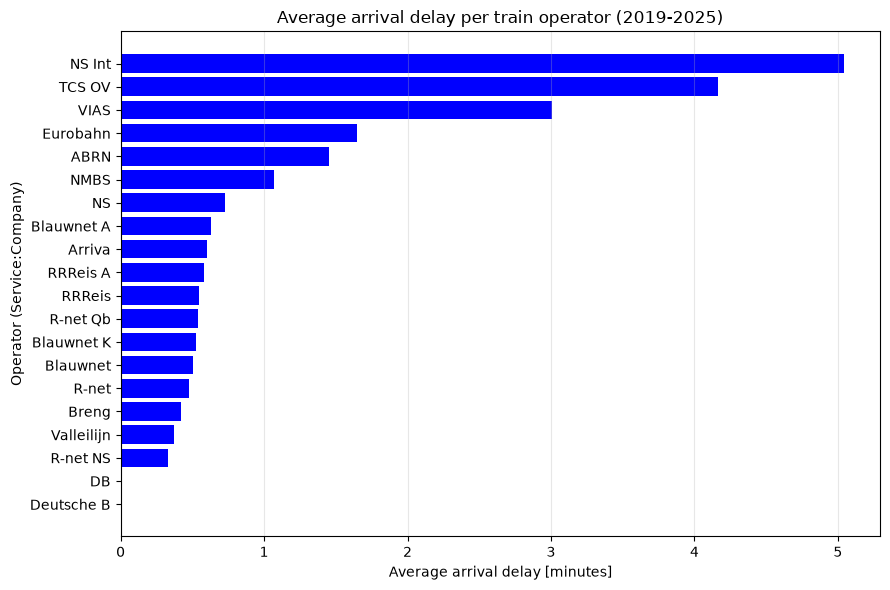

In [19]:
df = con.sql("""
SELECT "Service:Company" AS company, avg("Stop:Arrival delay") AS avg_arrival_delay
FROM services
WHERE NOT regexp_matches("Service:Type", 'bus|tram|metro', 'i')
GROUP BY company
HAVING count("Stop:Arrival delay") >= 10000
ORDER BY avg_arrival_delay
""").df()

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(df["company"], df["avg_arrival_delay"], color="blue")
ax.set_title("Average arrival delay per train operator (2019-2025)")
ax.set_xlabel("Average arrival delay [minutes]")
ax.set_ylabel("Operator (Service:Company)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## 7.8 How many services were disrupted in different years? Make a line plot.

In [20]:
disruptions = con.sql("""
SELECT rdt_id, rdt_station_codes, start_time, end_time
FROM pg.disruptions
WHERE year(start_time) >= 2019
""").df()
disruptions.head()

,rdt_id,rdt_station_codes,start_time,end_time
0,25236,"GDM, HT, ZBM",2019-01-01 06:32:16,2019-01-01 06:33:31
1,25237,"ALMO, LLS",2019-01-01 07:12:00,2019-01-01 09:53:48
2,25238,"EML, HD, PT",2019-01-01 08:26:58,2019-01-01 08:44:01
3,25239,"CL, GDM, HTNC",2019-01-01 08:36:00,2019-01-01 09:09:43
4,25240,"AMF, AMFS, AVAT, EML, HD, HDE, NKK, NS, PT, WZ...",2019-01-01 09:45:48,2019-01-01 12:47:54


In [21]:
disruptions["station_code"] = disruptions["rdt_station_codes"].str.split(",")
disruption_stations = disruptions.explode("station_code")
disruption_stations["station_code"] = disruption_stations["station_code"].str.strip()
disruption_stations = disruption_stations[["rdt_id", "station_code", "start_time", "end_time"]]
disruption_stations.head()

,rdt_id,station_code,start_time,end_time
0,25236,GDM,2019-01-01 06:32:16,2019-01-01 06:33:31
0,25236,HT,2019-01-01 06:32:16,2019-01-01 06:33:31
0,25236,ZBM,2019-01-01 06:32:16,2019-01-01 06:33:31
1,25237,ALMO,2019-01-01 07:12:00,2019-01-01 09:53:48
1,25237,LLS,2019-01-01 07:12:00,2019-01-01 09:53:48


In [22]:
df = con.sql("""
SELECT year(s."Service:Date") AS year, count(DISTINCT s."Service:RDT-ID") AS disrupted_services
FROM services s
JOIN disruption_stations d ON s."Stop:Station code" = d.station_code
WHERE coalesce(s."Stop:Departure time", s."Stop:Arrival time") BETWEEN d.start_time AND d.end_time
GROUP BY year
ORDER BY year
""").df()
df

,year,disrupted_services
0,2019,282492
1,2020,275835
2,2021,304641
3,2022,449324
4,2023,474814


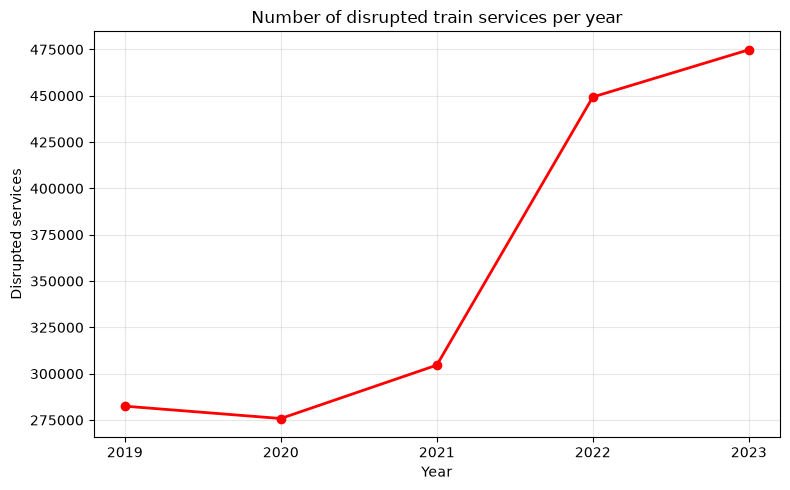

In [23]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(df["year"], df["disrupted_services"], marker="o", linewidth=2, color="red")
ax.set_title("Number of disrupted train services per year")
ax.set_xlabel("Year")
ax.set_ylabel("Disrupted services")
ax.set_xticks(df["year"])
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7.9 What fraction of all services were cancelled (Service:Completely cancelled) in different years? Make a line plot.

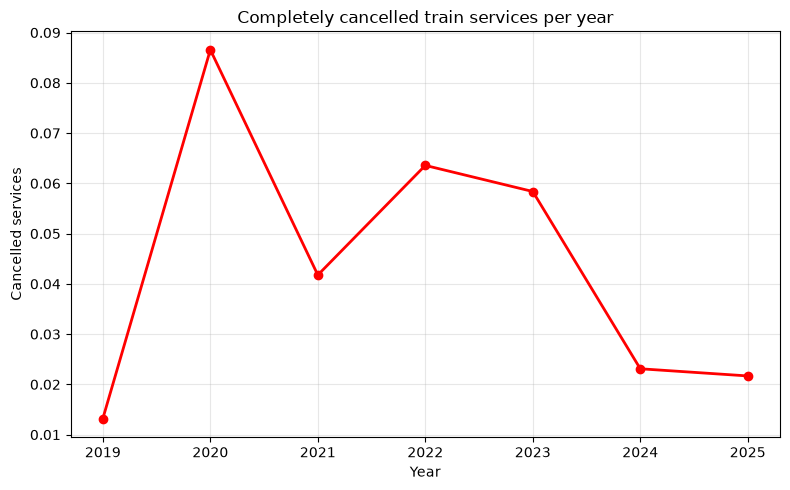

,year,cancelled_fraction
0,2019,0.013212
1,2020,0.086580
2,2021,0.041762
3,2022,0.063572
4,2023,0.058378
5,2024,0.023109
6,2025,0.021683


In [24]:
df = con.sql("""
SELECT year("Service:Date") AS year,
count(DISTINCT "Service:RDT-ID") FILTER ("Service:Completely cancelled")
    / count(DISTINCT "Service:RDT-ID") AS cancelled_fraction
FROM services
GROUP BY year
ORDER BY year
""").df()

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(df["year"], df["cancelled_fraction"], marker="o", linewidth=2, color="red")
ax.set_title("Completely cancelled train services per year")
ax.set_xlabel("Year")
ax.set_ylabel("Cancelled services")
ax.set_xticks(df["year"])
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
df

# 8. Distances by services

## 8.1 - 8.2 station_connections table

In [25]:
con.sql("""
CREATE OR REPLACE TEMP TABLE good_services AS
SELECT "Service:RDT-ID"
FROM services
WHERE "Service:Type" NOT ILIKE '%bus%'
AND "Service:Type" NOT ILIKE '%tram%'
AND "Service:Type" NOT ILIKE '%metro%'
AND "Stop:Departure time" IS NULL
GROUP BY "Service:RDT-ID"
HAVING count(*) = 1
""")
con.sql("SELECT count(*) AS good_services FROM good_services").df()

,good_services
0,15035558


In [26]:
con.sql("""
CREATE OR REPLACE TEMP TABLE pairs AS
SELECT s."Service:RDT-ID",
s."Stop:Station code" AS start_station_code,
LEAD(s."Stop:Station code") OVER (
PARTITION BY s."Service:RDT-ID"
ORDER BY s."Stop:Departure time" NULLS LAST, s."Stop:RDT-ID"
) AS end_station_code
FROM services s
JOIN good_services g ON s."Service:RDT-ID" = g."Service:RDT-ID"
""")

example_id = con.sql('SELECT min("Service:RDT-ID") FROM pairs').fetchone()[0]
con.sql(f'SELECT * FROM pairs WHERE "Service:RDT-ID" = {example_id}').df()

,Service:RDT-ID,start_station_code,end_station_code
0,738804,RTD,DT
1,738804,DT,GV
2,738804,GV,LEDN
3,738804,LEDN,SHL
4,738804,SHL,ASD
5,738804,ASD,UT
6,738804,UT,NaN


In [27]:
con.sql("""
CREATE OR REPLACE TEMP TABLE unique_pairs AS
SELECT least(start_station_code, end_station_code) AS start_station_code,
greatest(start_station_code, end_station_code) AS end_station_code,
min("Service:RDT-ID") AS "Service:RDT-ID"
FROM pairs
WHERE end_station_code IS NOT NULL
GROUP BY 1, 2
""")
con.sql("SELECT count(*) AS unique_pairs FROM unique_pairs").df()

,unique_pairs
0,2706


In [28]:
con.sql("""
CREATE OR REPLACE TABLE station_connections AS
SELECT p."Service:RDT-ID", p.start_station_code, p.end_station_code, d.distance
FROM unique_pairs p
JOIN distances_long d ON p.start_station_code = d.station AND p.end_station_code = d.other_station
""")
con.sql("FROM station_connections LIMIT 5").df()

,Service:RDT-ID,start_station_code,end_station_code,distance
0,738883,SRN,STD,7
1,739055,ST,STZ,1
2,8845782,ST,UT,19
3,14427778,ST,UTO,16
4,1549427,STD,TB,114


## 8.3 What is the largest distance between a pair of stations?

In [29]:
con.sql("""
SELECT c."Service:RDT-ID", s1.name_long AS start_station, s2.name_long AS a, c.distance
FROM station_connections c
JOIN stations s1 ON c.start_station_code = s1.code
JOIN stations s2 ON c.end_station_code = s2.code
ORDER BY c.distance DESC
LIMIT 1
""").df()

,Service:RDT-ID,start_station,a,distance
0,2364864,Alkmaar,Venlo,210


## 8.4 Plot a histogram of inter-station distances run by trains.

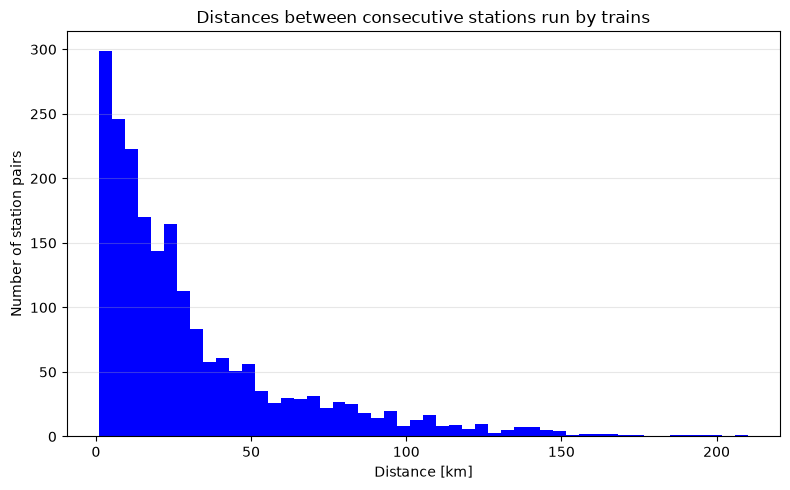

In [30]:
df = con.sql("SELECT distance FROM station_connections").df()

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(df["distance"], bins=50, color="blue")
ax.set_title("Distances between consecutive stations run by trains")
ax.set_xlabel("Distance [km]")
ax.set_ylabel("Number of station pairs")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()